In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
sns.set_theme()

In [4]:
data = pd.read_csv("titanic.csv")

print("Dimensions du dataset :", data.shape)
display(data.head())

print("\nInformations sur les colonnes :")
data.info()

print("\nValeurs manquantes par colonne :")
display(data.isnull().sum().to_frame("Valeurs manquantes"))

print("\nStatistiques descriptives :")
display(data.describe(include="all").T)

Dimensions du dataset : (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Informations sur les colonnes :
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Valeurs manquantes par colonne :


,Valeurs manquantes
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0



Statistiques descriptives :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


,Nombre
Survived,
Non survivant,549
Survivant,342


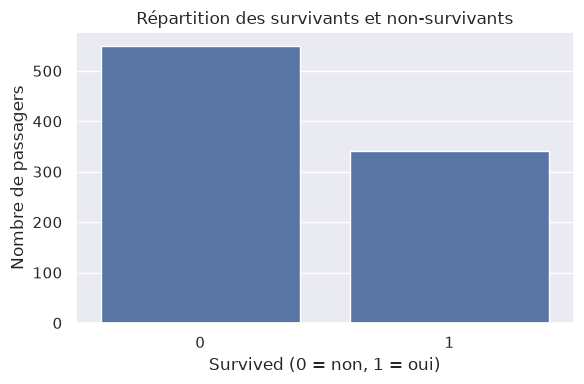

In [5]:
survival_counts = data["Survived"].value_counts().sort_index()
display(survival_counts.rename(index={0: "Non survivant", 1: "Survivant"}).to_frame("Nombre"))

plt.figure(figsize=(6, 4))
sns.countplot(data=data, x="Survived")
plt.title("Répartition des survivants et non-survivants")
plt.xlabel("Survived (0 = non, 1 = oui)")
plt.ylabel("Nombre de passagers")
plt.tight_layout()
plt.show()

In [6]:
data = data[[
    "Survived", "Pclass", "Sex", "Age",
    "SibSp", "Parch", "Fare", "Embarked"
]].copy()

data["Age"] = data["Age"].fillna(data["Age"].median())
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

print("Valeurs manquantes après nettoyage :")
display(data.isnull().sum().to_frame("Valeurs manquantes"))
display(data.head())

Valeurs manquantes après nettoyage :


,Valeurs manquantes
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [7]:
le_sex = LabelEncoder()
le_embarked = LabelEncoder()

data["Sex"] = le_sex.fit_transform(data["Sex"])
data["Embarked"] = le_embarked.fit_transform(data["Embarked"])

print("Encodage de Sex :", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("Encodage de Embarked :", dict(zip(le_embarked.classes_, le_embarked.transform(le_embarked.classes_))))
display(data.head())

Encodage de Sex : {'female': np.int64(0), 'male': np.int64(1)}
Encodage de Embarked : {'C': np.int64(0), 'Q': np.int64(1), 'S': np.int64(2)}


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


In [8]:
X = data.drop("Survived", axis=1)
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (712, 7)
X_test  : (179, 7)
y_train : (712,)
y_test  : (179,)


In [9]:
# Modèle 1 : régression logistique (classification)
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

# Modèle 2 : Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)

print("Les deux modèles sont entraînés.")

Les deux modèles sont entraînés.


In [10]:
y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

accuracy_log = accuracy_score(y_test, y_pred_log)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(f"Accuracy (Logistic Regression) : {accuracy_log:.3f}")
print(f"Accuracy (Random Forest)       : {accuracy_rf:.3f}")

print("\nRapport de classification — Régression logistique")
print(classification_report(y_test, y_pred_log, target_names=["Non survivant", "Survivant"]))

print("\nRapport de classification — Random Forest")
print(classification_report(y_test, y_pred_rf, target_names=["Non survivant", "Survivant"]))

Accuracy (Logistic Regression) : 0.804
Accuracy (Random Forest)       : 0.827

Rapport de classification — Régression logistique
               precision    recall  f1-score   support

Non survivant       0.81      0.89      0.85       110
    Survivant       0.79      0.67      0.72        69

     accuracy                           0.80       179
    macro avg       0.80      0.78      0.79       179
 weighted avg       0.80      0.80      0.80       179


Rapport de classification — Random Forest
               precision    recall  f1-score   support

Non survivant       0.84      0.89      0.86       110
    Survivant       0.81      0.72      0.76        69

     accuracy                           0.83       179
    macro avg       0.82      0.81      0.81       179
 weighted avg       0.83      0.83      0.82       179



In [11]:
comparison = pd.DataFrame({
    "Modèle": ["Régression logistique", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf)
    ]
}).sort_values("Accuracy", ascending=False)

display(comparison)

,Modèle,Accuracy
1,Random Forest,0.826816
0,Régression logistique,0.804469


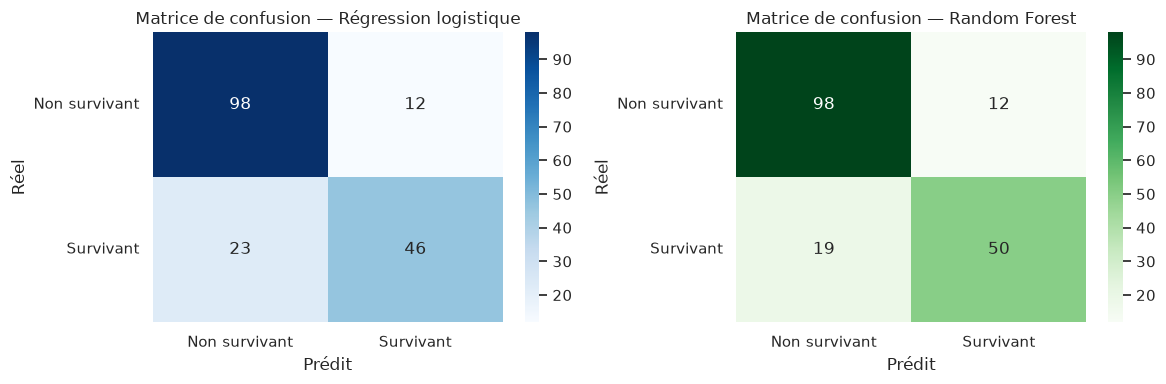

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm_log = confusion_matrix(y_test, y_pred_log)
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_log, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Matrice de confusion — Régression logistique")
axes[0].set_xlabel("Prédit")
axes[0].set_ylabel("Réel")
axes[0].set_xticklabels(["Non survivant", "Survivant"])
axes[0].set_yticklabels(["Non survivant", "Survivant"], rotation=0)

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Matrice de confusion — Random Forest")
axes[1].set_xlabel("Prédit")
axes[1].set_ylabel("Réel")
axes[1].set_xticklabels(["Non survivant", "Survivant"])
axes[1].set_yticklabels(["Non survivant", "Survivant"], rotation=0)

plt.tight_layout()
plt.show()

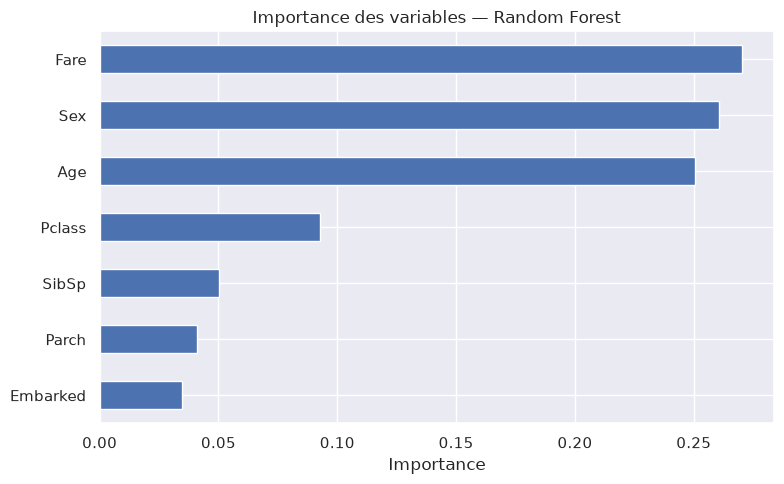

,Importance
Fare,0.270237
Sex,0.260625
Age,0.250389
Pclass,0.092549
SibSp,0.050297
Parch,0.041084
Embarked,0.034820


In [13]:
importances = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind="barh")
plt.title("Importance des variables — Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(importances.sort_values(ascending=False).to_frame("Importance"))